# AUPRC by number of 2019 wetland pixels per cell

Validation AUPRC for the hurdle classifier (any 2019 wetland in the cell developed by 2024, `n_developed > 0`), split by how many 30m wetland pixels the cell held in 2019. One figure per cell size, read from `results/hurdle_clf_mlp_{300m,3km}/auprc_by_n_wetland.csv`.

Each bar is the mean over the 5 spatial folds and the error bar is the standard deviation across folds. The gray line across each bar is the positive rate in that bin, which is the AUPRC a random ranking would get. Since the positive rate moves a lot across bins, compare each bar to its own gray line, not across bins.

The 300m CSV also scores the TCN share regressor, but only the classifier is plotted here.

The bins are the same at both resolutions, so at 3km almost every cell lands in 91+. The "1" bin at 3km has positives in only 2 of 5 folds (3 folds have AUPRC undefined), so that bar is a mean over 2 folds and a handful of cells, and its std comes from just those 2.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RUNS = {
    "300m": ROOT / "results/hurdle_clf_mlp_300m",
    "3km": ROOT / "results/hurdle_clf_mlp_3km",
}
FIG_DIR = ROOT / "results/figures/prediction_analysis"
FIG_DIR.mkdir(parents=True, exist_ok=True)
BIN_ORDER = ["1", "2 to 15", "16 to 44", "45 to 90", "91+"]

auprc = {}
for res, d in RUNS.items():
    m = json.loads((d / "manifest.json").read_text())
    c = m["cells"]
    print(f"{res:>5}  {m['model']}  {m['loss']}  cells {c['path']} built {c['built_utc']} "
          f"commit {c['git_commit'][:7]}  n_cells {c['n_cells']:,}  "
          f"positive share {c['share_cells_with_any_developed']:.2%}")
    df = pd.read_csv(d / "auprc_by_n_wetland.csv", dtype={"n_wetland_bin": str})
    df = df[df["model"] == "classifier"].copy()
    df["n_pos"] = (df["positive_rate"] * df["n_cells"]).round().astype(int)
    auprc[res] = df

 300m  CellMultiLayerPerceptronClassifier  focal loss  cells data/cells_2019_2024_300m built 2026-10-01T22:44:28Z commit 868089f  n_cells 1,170,463  positive share 3.06%
  3km  CellMultiLayerPerceptronClassifier  focal loss  cells data/cells_2019_2024_3km built 2026-11-03T20:21:41Z commit 52ebf47  n_cells 23,900  positive share 28.60%


In [2]:
# folds are disjoint validation sets, so summing cells over folds counts each cell once
summary = {}
for res, df in auprc.items():
    g = df.groupby("n_wetland_bin")
    s = g.agg(n_cells=("n_cells", "sum"), n_pos=("n_pos", "sum"),
              folds_scored=("auprc", "count"),
              auprc_mean=("auprc", "mean"), auprc_std=("auprc", "std"), auprc_min=("auprc", "min"), auprc_max=("auprc", "max"))
    s["positive_rate"] = s["n_pos"] / s["n_cells"]
    s = s.reindex(BIN_ORDER)
    summary[res] = s
    print(res)
    display(s.round(3))

300m


,n_cells,n_pos,folds_scored,auprc_mean,auprc_std,auprc_min,auprc_max,positive_rate
n_wetland_bin,,,,,,,,
1,33604,998,5,0.265,0.021,0.248,0.301,0.030
2 to 15,252903,11203,5,0.364,0.030,0.324,0.398,0.044
16 to 44,299094,12760,5,0.427,0.040,0.368,0.478,0.043
45 to 90,289574,9677,5,0.387,0.080,0.277,0.500,0.033
91+,295288,1214,5,0.220,0.060,0.178,0.326,0.004


3km


,n_cells,n_pos,folds_scored,auprc_mean,auprc_std,auprc_min,auprc_max,positive_rate
n_wetland_bin,,,,,,,,
1,87,2,2,0.333,0.236,0.167,0.500,0.023
2 to 15,647,64,5,0.428,0.082,0.309,0.499,0.099
16 to 44,714,147,5,0.629,0.165,0.443,0.789,0.206
45 to 90,712,217,5,0.788,0.024,0.756,0.813,0.305
91+,21740,6405,5,0.844,0.010,0.834,0.859,0.295


In [3]:
BAR_COLOR = "#2a78d6"
CHANCE_COLOR = "#52514e"
RES_TITLE = {"300m": "300 m cells", "3km": "3 km cells"}

plt.rcParams.update({"font.size": 14, "axes.titlesize": 16, "axes.labelsize": 15,
                     "xtick.labelsize": 12, "ytick.labelsize": 13, "legend.fontsize": 13})


def plot_auprc_by_bin(res):
    s = summary[res]
    x = np.arange(len(BIN_ORDER))
    width = 0.6

    fig, ax = plt.subplots(figsize=(9, 5.5))
    # pandas std is ddof=1, so a bin scored in only 1 fold would get NaN and no error bar
    ax.bar(x, s["auprc_mean"], width=width, color=BAR_COLOR, label="MLP classifier, mean ± std over folds",
           yerr=s["auprc_std"], error_kw=dict(ecolor="#0b0b0b", elinewidth=1.5, capsize=6, capthick=1.5),
           zorder=2)
    ax.hlines(s["positive_rate"], x - width / 2, x + width / 2, color=CHANCE_COLOR, lw=2.5, ls="--",
              label="Positive rate (random ranking)", zorder=3)

    ticks = [f"{b}\n{s.loc[b, 'n_cells']:,} cells\n{s.loc[b, 'n_pos']:,} pos" for b in BIN_ORDER]
    ax.set_xticks(x, ticks)
    ax.set_ylim(0, 1)
    ax.set_xlabel("2019 wetland pixels (30 m) in cell")
    ax.set_ylabel("AUPRC")
    ax.set_title(f"Wetland to developed AUPRC by cell wetland area, {RES_TITLE[res]}")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False, loc="upper left")
    fig.tight_layout()
    return fig

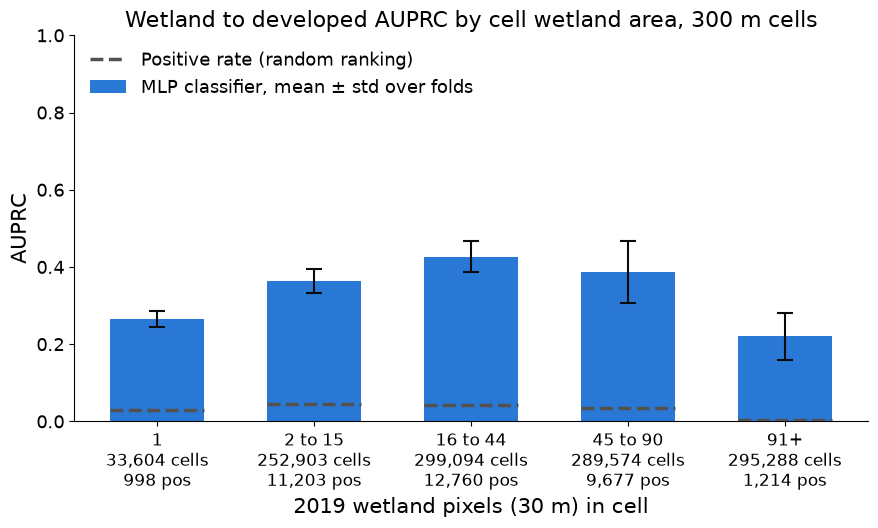

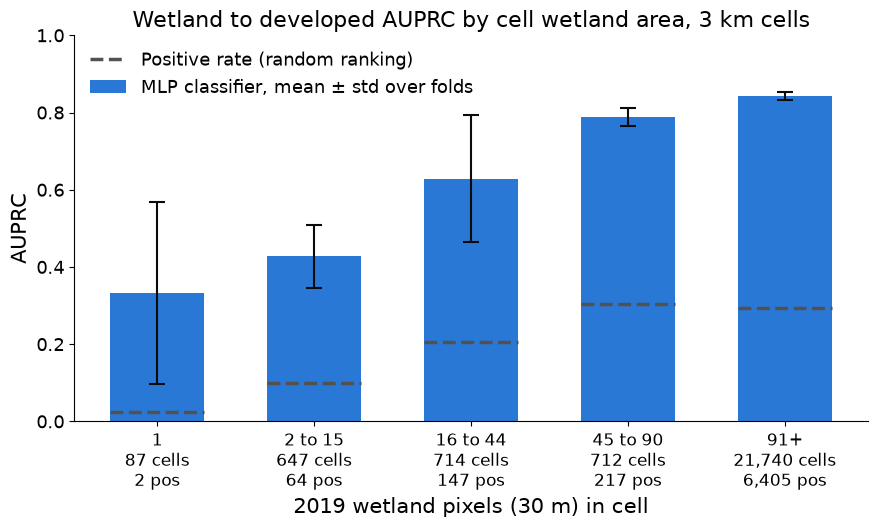

In [4]:
for res in RUNS:
    fig = plot_auprc_by_bin(res)
    fig.savefig(FIG_DIR / f"auprc_by_n_wetland_{res}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()